<Axes: >

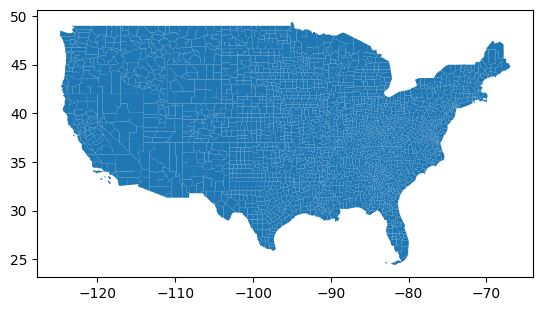

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
gdf= gpd.read_file("/home/s0shar47/scratch/OUTPUTS_Paper1/gdf_conus/gdf_conus.shp")
locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
gdf.plot()

In [7]:
import geopandas as gpd
import pandas as pd

# Convert gauge locations to a GeoDataFrame
locations_gdf = gpd.GeoDataFrame(
    locations,
    geometry=gpd.points_from_xy(locations["LONG"], locations["LAT"]),
    crs="EPSG:4326"
)

# Make sure county polygons use the same CRS
gdf = gdf.to_crs(locations_gdf.crs)

# Spatial join
locations_with_county = gpd.sjoin(
    locations_gdf,
    gdf[["NAME", "STATE_NAME", "geometry"]],
    how="left",
    predicate="within"
).drop(columns="index_right")

# Rename columns
locations_with_county = locations_with_county.rename(
    columns={
        "NAME": "COUNTY_NAME",
        "STATE_NAME": "STATE_NAME"
    }
)

# If you don't need the geometry column afterwards
locations = pd.DataFrame(locations_with_county.drop(columns="geometry"))

locations

,HUC_02,GAGE_ID,GAGE_NAME,LAT,LONG,DRAINAGE AREA (KM^2),COUNTY_NAME,STATE_NAME_left,COUNTY_NAME,STATE_NAME_right,COUNTY_NAME,STATE_NAME
0,1,1013500,"Fish River near Fort Kent, Maine",47.23739,-68.58264,2252.70,Aroostook,Maine,Aroostook,Maine,Aroostook,Maine
1,1,1022500,"Narraguagus River at Cherryfield, M...",44.60797,-67.93524,573.60,Washington,Maine,Washington,Maine,Washington,Maine
2,1,1030500,"Mattawamkeag River near Mattawamkeag, M...",45.50097,-68.30596,3676.17,Penobscot,Maine,Penobscot,Maine,Penobscot,Maine
3,1,1031500,"Piscataquis River near Dover-Foxcroft, M...",45.17501,-69.31470,769.05,Piscataquis,Maine,Piscataquis,Maine,Piscataquis,Maine
4,1,1047000,"Carrabassett River near North Anson, M...",44.86920,-69.95510,909.10,Somerset,Maine,Somerset,Maine,Somerset,Maine
...,...,...,...,...,...,...,...,...,...,...,...,...
666,17,14309500,WEST FORK COW CREEK NEAR GLENDALE...,42.80400,-123.61091,224.92,Douglas,Oregon,Douglas,Oregon,Douglas,Oregon
667,17,14316700,STEAMBOAT CREEK NEAR GLIDE...,43.34984,-122.72894,587.90,Douglas,Oregon,Douglas,Oregon,Douglas,Oregon
668,17,14325000,SOUTH FORK COQUILLE RIVER AT POWERS...,42.89150,-124.07065,443.07,Coos,Oregon,Coos,Oregon,Coos,Oregon
669,17,14362250,"STAR GULCH NEAR RUCH,...",42.15401,-123.07532,41.42,Jackson,Oregon,Jackson,Oregon,Jackson,Oregon


In [10]:
floods= pd.read_csv("/home/s0shar47/scratch/OUTPUTS_Paper1/FlashFloods.csv")
locations.columns

Index(['HUC_02', 'GAGE_ID', 'GAGE_NAME', 'LAT', 'LONG', 'DRAINAGE AREA (KM^2)',
       'COUNTY_NAME', 'STATE_NAME_left', 'COUNTY_NAME', 'STATE_NAME_right',
       'COUNTY_NAME', 'STATE_NAME'],
      dtype='object')

In [14]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from geopy.distance import geodesic


# -----------------------------
# Load data
# -----------------------------
floods= pd.read_csv("/home/s0shar47/scratch/OUTPUTS_Paper1/FlashFloods.csv")

locations = pd.read_csv(
    "/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv"
)

# -----------------------------
# Clean county/state names
# -----------------------------

floods["COUNTY_CLEAN"] = (
    floods["CZ_NAME"]
    .str.upper()
    .str.replace(" COUNTY", "", regex=False)
    .str.strip()
)

locations["COUNTY_CLEAN"] = (
    locations["COUNTY_NAME"]
    .str.upper()
    .str.replace(" COUNTY", "", regex=False)
    .str.strip()
)

floods["STATE_CLEAN"] = floods["STATE"].str.upper().str.strip()

locations["STATE_CLEAN"] = (
    locations["STATE_NAME"]
    .str.upper()
    .str.strip()
)


# -----------------------------
# Convert to GeoDataFrames
# -----------------------------

flood_gdf = gpd.GeoDataFrame(
    floods,
    geometry=[
        Point(xy) for xy in zip(floods.LONGITUDE, floods.LATITUDE)
    ],
    crs="EPSG:4326"
)

gage_gdf = gpd.GeoDataFrame(
    locations,
    geometry=[
        Point(xy) for xy in zip(locations.LONG, locations.LAT)
    ],
    crs="EPSG:4326"
)


# -----------------------------
# Function to calculate distance
# -----------------------------

def distance_km(point1, point2):
    return geodesic(
        (point1.y, point1.x),
        (point2.y, point2.x)
    ).km



# -----------------------------
# Assign gauges
# -----------------------------

assigned = []

for idx, flood in flood_gdf.iterrows():

    state = flood["STATE_CLEAN"]
    county = flood["COUNTY_CLEAN"]


    # gauges in same county
    same_county = gage_gdf[
        (gage_gdf.STATE_CLEAN == state) &
        (gage_gdf.COUNTY_CLEAN == county)
    ]


    if len(same_county) > 0:

        # choose closest gauge in county
        distances = same_county.geometry.apply(
            lambda x: distance_km(flood.geometry, x)
        )

        best = same_county.loc[distances.idxmin()]

        assigned.append(
            {
                "ASSIGNED_GAGE_ID": best.GAGE_ID,
                "ASSIGNED_GAGE_NAME": best.GAGE_NAME,
                "GAGE_DISTANCE_KM": distances.min(),
                "MATCH_TYPE": "same_county"
            }
        )


    else:

        # no gauge in county --> nearest gauge anywhere

        distances = gage_gdf.geometry.apply(
            lambda x: distance_km(flood.geometry, x)
        )

        best_idx = distances.idxmin()

        best = gage_gdf.loc[best_idx]


        assigned.append(
            {
                "ASSIGNED_GAGE_ID": best.GAGE_ID,
                "ASSIGNED_GAGE_NAME": best.GAGE_NAME,
                "GAGE_DISTANCE_KM": distances.min(),
                "MATCH_TYPE": "nearest_gage"
            }
        )



# -----------------------------
# Add results
# -----------------------------

assigned_df = pd.DataFrame(assigned)

floods_assigned = pd.concat(
    [
        floods.reset_index(drop=True),
        assigned_df
    ],
    axis=1
)


# save
# floods_assigned.to_csv(
#     "floods_with_assigned_gages.csv",
#     index=False
# )


display(floods_assigned)
print(
    floods_assigned.MATCH_TYPE.value_counts()
)

KeyError: 'COUNTY_NAME'

In [ ]:
floods= pd.read_csv("/home/s0shar47/scratch/OUTPUTS_Paper1/FlashFloods.csv")
floods

,STATE,EVENT_TYPE,CZ_NAME,FLOOD_CAUSE,EPISODE_NARRATIVE,DATA_SOURCE,LOCATION,LATITUDE,LONGITUDE,Start_Date,Start_Time,End_Date,End_Time
0,OKLAHOMA,Flash Flood,BRYAN,NaN,Flash flood waters washed out a small bridge a...,PDC,DURANT,NaN,NaN,1996-10-21,09:00,1996-10-21,09:00
1,NEW YORK,Flash Flood,BROOME,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,08:30,1996-01-20,07:00
2,NEW YORK,Flash Flood,ONEIDA,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,08:30,1996-01-20,07:00
3,VIRGINIA,Flash Flood,WYTHE,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,04:30,1996-01-19,06:00
4,RHODE ISLAND,Flash Flood,BRISTOL,NaN,Snow quickly changed to heavy rain and resulte...,PDC,NaN,NaN,NaN,1996-01-12,17:00,1996-01-12,23:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15181,UTAH,Flash Flood,MORGAN,NaN,Heavy monsoonal rains were widespread over Nor...,PDC,COUNTYWIDE,NaN,NaN,2000-08-30,12:00,2000-08-31,18:00
15182,PENNSYLVANIA,Flash Flood,LACKAWANNA,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,10:00,2000-12-17,15:00
15183,NEW YORK,Flash Flood,SULLIVAN,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,10:00,2000-12-17,23:00
15184,NEW YORK,Flash Flood,DELAWARE,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,11:00,2000-12-17,23:00


In [18]:
print('locations.columns')
print(locations.columns)
print('floods.columns')
print(floods.columns)
print('gdf.columns')
print(gdf.columns)

locations.columns
Index(['HUC_02', 'GAGE_ID', 'GAGE_NAME', 'LAT', 'LONG',
       'DRAINAGE AREA (KM^2)'],
      dtype='object')
floods.columns
Index(['STATE', 'EVENT_TYPE', 'CZ_NAME', 'FLOOD_CAUSE', 'EPISODE_NARRATIVE',
       'DATA_SOURCE', 'LOCATION', 'LATITUDE', 'LONGITUDE', 'Start_Date',
       'Start_Time', 'End_Date', 'End_Time', 'COUNTY_CLEAN'],
      dtype='object')
gdf.columns
Index(['STATEFP', 'COUNTYFP', 'COUNTYNS', 'GEOID', 'NAME', 'NAMELSAD', 'LSAD',
       'CLASSFP', 'MTFCC', 'CSAFP', 'CBSAFP', 'METDIVFP', 'FUNCSTAT', 'ALAND',
       'AWATER', 'INTPTLAT', 'INTPTLON', 'STATE_NAME', 'geometry'],
      dtype='object')


In [48]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import re


# =====================================================
# Load data
# =====================================================

gdf = gpd.read_file(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/gdf_conus/gdf_conus.shp"
)

locations = pd.read_csv(
    "/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv"
)

# floods already loaded


# =====================================================
# Cleaning function
# =====================================================

def clean_name(x):

    x = str(x).upper().strip()

    # remove brackets
    x = re.sub(r"\(.*?\)", "", x)

    # replace hyphen with space
    x = x.replace("-", " ")

    # remove county type names
    x = re.sub(
        r"\b(COUNTY|PARISH|BOROUGH|MUNICIPALITY|CITY AND BOROUGH)\b",
        "",
        x
    )

    # remove periods
    x = x.replace(".", "")

    # remove extra spaces
    x = re.sub(
        r"\s+",
        " ",
        x
    )

    return x.strip()



# =====================================================
# County shapefile
# =====================================================

county_gdf = gdf[
    [
        "STATE_NAME",
        "NAME",
        "geometry"
    ]
].copy()


county_gdf = county_gdf.to_crs(
    "EPSG:4326"
)


county_gdf["STATE_CLEAN"] = (
    county_gdf["STATE_NAME"]
    .apply(clean_name)
)


county_gdf["COUNTY_CLEAN"] = (
    county_gdf["NAME"]
    .apply(clean_name)
)



# =====================================================
# Flood county names
# =====================================================

floods = floods.copy()


floods["STATE_CLEAN"] = (
    floods["STATE"]
    .apply(clean_name)
)


floods["COUNTY_CLEAN"] = (
    floods["CZ_NAME"]
    .apply(clean_name)
)



# =====================================================
# Match flood county with polygons
# =====================================================

floods_county = floods.merge(
    county_gdf[
        [
            "STATE_CLEAN",
            "COUNTY_CLEAN",
            "geometry"
        ]
    ],
    how="left",
    on=[
        "STATE_CLEAN",
        "COUNTY_CLEAN"
    ]
)


floods_county = gpd.GeoDataFrame(
    floods_county,
    geometry="geometry",
    crs="EPSG:4326"
)


print(
    "Floods without county geometry:",
    floods_county.geometry.isna().sum()
)


if floods_county.geometry.isna().sum()>0:

    print(
        floods_county[
            floods_county.geometry.isna()
        ][
            [
                "STATE",
                "CZ_NAME"
            ]
        ].head(20)
    )



# =====================================================
# Prepare gauge locations
# =====================================================

gage_gdf = gpd.GeoDataFrame(
    locations.copy(),
    geometry=[
        Point(x,y)
        for x,y in zip(
            locations["LONG"],
            locations["LAT"]
        )
    ],
    crs="EPSG:4326"
)



# =====================================================
# Assign county to gauges
# =====================================================

gage_gdf = gpd.sjoin(
    gage_gdf,
    county_gdf[
        [
            "STATE_CLEAN",
            "COUNTY_CLEAN",
            "geometry"
        ]
    ],
    how="left",
    predicate="intersects"
)


if "index_right" in gage_gdf.columns:
    gage_gdf = gage_gdf.drop(
        columns="index_right"
    )


print("\nGauge county check:")
print(
    gage_gdf[
        [
            "GAGE_ID",
            "STATE_CLEAN",
            "COUNTY_CLEAN"
        ]
    ].head()
)



# =====================================================
# Convert to equal area CRS
# =====================================================

floods_county = floods_county.to_crs(
    "EPSG:5070"
)

gage_gdf = gage_gdf.to_crs(
    "EPSG:5070"
)



# create county representative point AFTER projection

floods_county["COUNTY_POINT"] = (
    floods_county.geometry
    .representative_point()
)



# =====================================================
# Assign gauges
# =====================================================

assigned=[]


for idx,row in floods_county.iterrows():

    point = row["COUNTY_POINT"]

    state = row["STATE_CLEAN"]

    county = row["COUNTY_CLEAN"]


    # no polygon match

    if point is None or pd.isna(point):

        assigned.append(
            {
                "GAGE_ID":None,
                "GAGE_NAME":None,
                "DISTANCE_KM":None,
                "MATCH_TYPE":"no_county_match"
            }
        )

        continue



    # same county gauges

    candidates = gage_gdf[
        (gage_gdf["STATE_CLEAN"]==state) &
        (gage_gdf["COUNTY_CLEAN"]==county)
    ]


    if len(candidates)>0:


        distances = (
            candidates.geometry.distance(point)
            /
            1000
        )


        best = candidates.loc[
            distances.idxmin()
        ]


        assigned.append(
            {
                "GAGE_ID":best["GAGE_ID"],
                "GAGE_NAME":best["GAGE_NAME"],
                "DISTANCE_KM":distances.min(),
                "MATCH_TYPE":"same_county"
            }
        )


    else:


        # nearest gauge anywhere

        distances = (
            gage_gdf.geometry.distance(point)
            /
            1000
        )


        best = gage_gdf.loc[
            distances.idxmin()
        ]


        assigned.append(
            {
                "GAGE_ID":best["GAGE_ID"],
                "GAGE_NAME":best["GAGE_NAME"],
                "DISTANCE_KM":distances.min(),
                "MATCH_TYPE":"nearest_gage"
            }
        )



# =====================================================
# Combine
# =====================================================

assigned_df = pd.DataFrame(assigned)


floods_assigned = pd.concat(
    [
        floods_county.drop(
            columns=[
                "geometry",
                "COUNTY_POINT"
            ]
        ).reset_index(drop=True),

        assigned_df
    ],
    axis=1
)



# =====================================================
# Save
# =====================================================

outfile = (
    "/home/s0shar47/scratch/OUTPUTS_Paper1/"
    "floods_assigned_gauges.csv"
)


floods_assigned.to_csv(
    outfile,
    index=False
)


print("\nSaved:", outfile)


print("\nMatch summary:")
print(
    floods_assigned["MATCH_TYPE"]
    .value_counts()
)


print("\nExample:")
display(
    floods_assigned[
        [
            "STATE",
            "CZ_NAME",
            "GAGE_ID",
            "GAGE_NAME",
            "DISTANCE_KM",
            "MATCH_TYPE"
        ]
    ].head(20)
)

Floods without county geometry: 314
             STATE                       CZ_NAME
44    RHODE ISLAND                  EASTERN KENT
70    RHODE ISLAND                  WESTERN KENT
81        MARYLAND            BALTIMORE CITY (C)
121   RHODE ISLAND          NORTHWEST PROVIDENCE
143   RHODE ISLAND          SOUTHEAST PROVIDENCE
217    PUERTO RICO                      CAROLINA
242         HAWAII                      HONOLULU
259        INDIANA                       DE KALB
408         HAWAII                        HAWAII
479        INDIANA                      LA PORTE
484       MARYLAND            BALTIMORE CITY (C)
593       ILLINOIS                       DE KALB
678       ILLINOIS                      LA SALLE
805       MISSOURI                       DE KALB
834       MARYLAND            BALTIMORE CITY (C)
869       MARYLAND            BALTIMORE CITY (C)
1082       INDIANA                       DE KALB
1158        OREGON  WESTERN COLUMBIA RIVER GORGE
1252         TEXAS               

,STATE,CZ_NAME,GAGE_ID,GAGE_NAME,DISTANCE_KM,MATCH_TYPE
0,OKLAHOMA,BRYAN,8050800.0,Timber Ck nr Collinsville...,76.440062,nearest_gage
1,NEW YORK,BROOME,1510000.0,OTSELIC RIVER AT CINCINNATU...,43.223124,nearest_gage
2,NEW YORK,ONEIDA,4256000.0,INDEPENDENCE RIVER AT DONNATTSBUR...,54.488671,nearest_gage
3,VIRGINIA,WYTHE,3164000.0,NEW RIVER NEAR GALAX...,30.963550,nearest_gage
4,RHODE ISLAND,BRISTOL,1118300.0,"PENDLETON HILL BROOK NEAR CLARKS FALLS,...",52.726565,nearest_gage
5,OHIO,ATHENS,3159540.0,Shade River near Cheste...,37.665060,nearest_gage
6,OHIO,GALLIA,3159540.0,Shade River near Cheste...,52.492134,nearest_gage
7,PENNSYLVANIA,WARREN,3015500.0,Brokenstraw Creek at Youngsville...,5.208009,same_county
8,PENNSYLVANIA,SULLIVAN,1552500.0,Muncy Creek near Sonestown...,9.312753,same_county
9,VIRGINIA,CAMPBELL,2064000.0,FALLING RIVER NEAR NARUNA...,14.717066,same_county


In [49]:
floods_assigned

,STATE,EVENT_TYPE,CZ_NAME,FLOOD_CAUSE,EPISODE_NARRATIVE,DATA_SOURCE,LOCATION,LATITUDE,LONGITUDE,Start_Date,Start_Time,End_Date,End_Time,COUNTY_CLEAN,STATE_CLEAN,GAGE_ID,GAGE_NAME,DISTANCE_KM,MATCH_TYPE
0,OKLAHOMA,Flash Flood,BRYAN,NaN,Flash flood waters washed out a small bridge a...,PDC,DURANT,NaN,NaN,1996-10-21,09:00,1996-10-21,09:00,BRYAN,OKLAHOMA,8050800.0,Timber Ck nr Collinsville...,76.440062,nearest_gage
1,NEW YORK,Flash Flood,BROOME,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,08:30,1996-01-20,07:00,BROOME,NEW YORK,1510000.0,OTSELIC RIVER AT CINCINNATU...,43.223124,nearest_gage
2,NEW YORK,Flash Flood,ONEIDA,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,08:30,1996-01-20,07:00,ONEIDA,NEW YORK,4256000.0,INDEPENDENCE RIVER AT DONNATTSBUR...,54.488671,nearest_gage
3,VIRGINIA,Flash Flood,WYTHE,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,04:30,1996-01-19,06:00,WYTHE,VIRGINIA,3164000.0,NEW RIVER NEAR GALAX...,30.963550,nearest_gage
4,RHODE ISLAND,Flash Flood,BRISTOL,NaN,Snow quickly changed to heavy rain and resulte...,PDC,NaN,NaN,NaN,1996-01-12,17:00,1996-01-12,23:00,BRISTOL,RHODE ISLAND,1118300.0,"PENDLETON HILL BROOK NEAR CLARKS FALLS,...",52.726565,nearest_gage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15260,UTAH,Flash Flood,MORGAN,NaN,Heavy monsoonal rains were widespread over Nor...,PDC,COUNTYWIDE,NaN,NaN,2000-08-30,12:00,2000-08-31,18:00,MORGAN,UTAH,10023000.0,BIG CREEK NEAR RANDOLPH...,70.002038,nearest_gage
15261,PENNSYLVANIA,Flash Flood,LACKAWANNA,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,10:00,2000-12-17,15:00,LACKAWANNA,PENNSYLVANIA,1440400.0,Brodhead Creek near Analomink...,50.983694,nearest_gage
15262,NEW YORK,Flash Flood,SULLIVAN,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,10:00,2000-12-17,23:00,SULLIVAN,NEW YORK,1435000.0,NEVERSINK RIVER NEAR CLARYVILL...,23.511162,same_county
15263,NEW YORK,Flash Flood,DELAWARE,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,11:00,2000-12-17,23:00,DELAWARE,NEW YORK,1423000.0,WEST BRANCH DELAWARE RIVER AT WALTO...,12.745263,same_county


In [ ]:
floods_assigned.MATCH_TYPE.value_counts()

MATCH_TYPE
nearest_gage       12342
same_county         2609
no_county_match      314
Name: count, dtype: int64

In [50]:
floods_assigned[floods_assigned['MATCH_TYPE']=='nearest_gage'].sort_values(by='DISTANCE_KM', ascending= False)

,STATE,EVENT_TYPE,CZ_NAME,FLOOD_CAUSE,EPISODE_NARRATIVE,DATA_SOURCE,LOCATION,LATITUDE,LONGITUDE,Start_Date,Start_Time,End_Date,End_Time,COUNTY_CLEAN,STATE_CLEAN,GAGE_ID,GAGE_NAME,DISTANCE_KM,MATCH_TYPE
10835,TEXAS,Flash Flood,PRESIDIO,NaN,NaN,PDC,PAISANO,NaN,NaN,1999-07-28,16:00,1999-07-28,17:00,PRESIDIO,TEXAS,8190500.0,W Nueces Rv nr Brackettville...,390.793401,nearest_gage
10491,TEXAS,Flash Flood,PRESIDIO,NaN,This storm formed in northwestern Presidio Cou...,PDC,MARFA,NaN,NaN,1999-05-24,19:00,1999-05-24,20:00,PRESIDIO,TEXAS,8190500.0,W Nueces Rv nr Brackettville...,390.793401,nearest_gage
3544,TEXAS,Flash Flood,PRESIDIO,NaN,Upper level ridge which had suppressed convect...,PDC,PRESIDIO,NaN,NaN,1997-06-04,17:30,1997-06-04,20:00,PRESIDIO,TEXAS,8190500.0,W Nueces Rv nr Brackettville...,390.793401,nearest_gage
2078,TEXAS,Flash Flood,PRESIDIO,NaN,NaN,PDC,MARFA,NaN,NaN,1996-09-11,17:30,1996-09-11,18:15,PRESIDIO,TEXAS,8190500.0,W Nueces Rv nr Brackettville...,390.793401,nearest_gage
15132,TEXAS,Flash Flood,PRESIDIO,NaN,Scattered thunderstorms developed over the nor...,PDC,CASA PIEDRA,NaN,NaN,2000-06-17,15:30,2000-06-17,18:00,PRESIDIO,TEXAS,8190500.0,W Nueces Rv nr Brackettville...,390.793401,nearest_gage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5613,VIRGINIA,Flash Flood,DANVILLE (C),NaN,Heavy rain during the late evening hours on th...,PDC,DANVILLE,NaN,NaN,1997-04-29,05:05,1997-04-29,08:30,DANVILLE,VIRGINIA,2074500.0,SANDY RIVER NEAR DANVILLE...,8.983285,nearest_gage
11004,VIRGINIA,Flash Flood,MIDDLESEX,NaN,Very heavy rain from Hurricane Floyd produced ...,PDC,COUNTYWIDE,NaN,NaN,1999-09-16,02:00,1999-09-16,20:00,MIDDLESEX,VIRGINIA,1669520.0,DRAGON SWAMP AT MASCOT...,6.337296,nearest_gage
14143,VIRGINIA,Flash Flood,MIDDLESEX,NaN,NaN,PDC,SALUDA,NaN,NaN,2000-09-02,20:00,2000-09-02,21:00,MIDDLESEX,VIRGINIA,1669520.0,DRAGON SWAMP AT MASCOT...,6.337296,nearest_gage
4188,VIRGINIA,Flash Flood,COVINGTON (C),NaN,Heavy rainfall during the afternoon and evenin...,PDC,COVINGTON,NaN,NaN,1997-06-01,14:15,1997-06-01,16:00,COVINGTON,VIRGINIA,2013000.0,DUNLAP CREEK NEAR COVINGTON...,5.799291,nearest_gage


  STATE_NAME      NAME
1      Texas  Presidio
     HUC_02  GAGE_ID                                          GAGE_NAME  \
472      12  8190500                    W Nueces Rv nr Brackettville...   

          LAT       LONG  DRAINAGE AREA (KM^2)  
472  29.47273 -100.23646               1799.09  


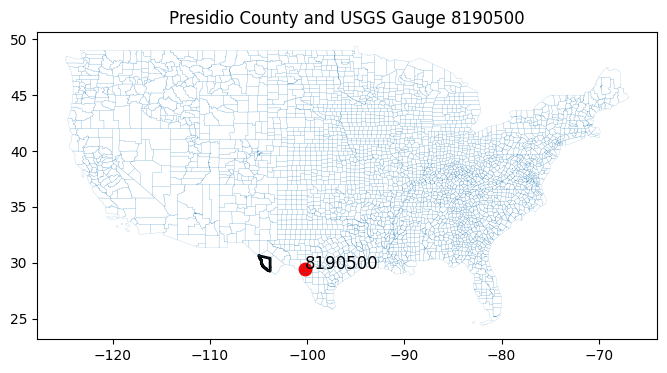

In [47]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point


# Load county shapefile
gdf = gpd.read_file(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/gdf_conus/gdf_conus.shp"
)


# Load gauge locations
locations = pd.read_csv(
    "/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv"
)


# -------------------------------
# Select Presidio county
# -------------------------------

presidio = gdf[
    gdf["NAME"].str.upper()=="PRESIDIO"
]


print(presidio[["STATE_NAME","NAME"]])


# -------------------------------
# Select gauge 8190500
# -------------------------------

gage = locations[
    locations["GAGE_ID"] == 8190500
]


print(gage)


gage_point = gpd.GeoDataFrame(
    gage,
    geometry=[
        Point(xy)
        for xy in zip(
            gage["LONG"],
            gage["LAT"]
        )
    ],
    crs="EPSG:4326"
)


# -------------------------------
# Plot
# -------------------------------

fig, ax = plt.subplots(figsize=(8,8))

gdf.boundary.plot(ax=ax, linewidth=0.08)
# county boundary
presidio.plot(
    ax=ax,
    edgecolor="black",
    facecolor="none",
    linewidth=2
)


# gauge point
gage_point.plot(
    ax=ax,
    color="red",
    markersize=80
)


# label gauge
for x, y, gid in zip(
    gage_point.geometry.x,
    gage_point.geometry.y,
    gage_point["GAGE_ID"]
):
    ax.text(
        x,
        y,
        str(int(gid)),
        fontsize=12
    )


ax.set_title(
    "Presidio County and USGS Gauge 8190500"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import os


test= "PUB"
tests= ['PUB', 'PUR']

# ==========================================================
# LOAD FLOOD ASSIGNMENTS
# ==========================================================

floods_assigned = pd.read_csv(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/floods_assigned_gauges.csv"
)


models = [
    "HBV",
    # "HBV_capillary",
    "marrmot_PRMS"
]

# methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
methods= ['Furey']

if test == 'PUB':
    n= 11
elif test == 'PUR':
    n= 8

# ==========================================================
# LOOP MODELS
# ==========================================================
for method in methods:

    for model in models:


        if model == "HBV":
            dyn = "parBETA_parBETAET_"

        elif model == "HBV_capillary":
            dyn = "parBETA_parBETAET_parK0_parUZL_"

        elif model == "marrmot_PRMS":
            dyn = "alpha_cgw_scx_tt_"


        floods_assigned = pd.read_csv("/home/s0shar47/scratch/OUTPUTS_Paper1/floods_assigned_gauges.csv")
        # ======================================================
        # METRIC FUNCTIONS
        # ======================================================

        def calc_nse(obs, sim):

            mask = np.isfinite(obs) & np.isfinite(sim)

            obs = obs[mask]
            sim = sim[mask]

            if len(obs) < 2:
                return np.nan

            den = np.sum(
                (obs - np.mean(obs)) ** 2
            )

            if den == 0:
                return np.nan

            return (
                1 -
                np.sum((obs - sim) ** 2) / den
            )



        def calc_kge(obs, sim):

            mask = np.isfinite(obs) & np.isfinite(sim)

            obs = obs[mask]
            sim = sim[mask]

            if len(obs) < 2:
                return np.nan

            if np.std(obs)==0 or np.mean(obs)==0:
                return np.nan


            r = np.corrcoef(
                obs,
                sim
            )[0,1]


            alpha = (
                np.std(sim)
                /
                np.std(obs)
            )


            beta = (
                np.mean(sim)
                /
                np.mean(obs)
            )


            return (
                1 -
                np.sqrt(
                    (r-1)**2 +
                    (alpha-1)**2 +
                    (beta-1)**2
                )
            )



        def calc_bias(obs, sim):

            mask = np.isfinite(obs) & np.isfinite(sim)

            obs = obs[mask]
            sim = sim[mask]

            if np.sum(obs)==0:
                return np.nan


            return (
                np.sum(sim)-np.sum(obs)
            ) / np.sum(obs)



        def calc_abs_bias(obs, sim):

            b = calc_bias(obs, sim)

            if np.isnan(b):
                return np.nan

            return abs(b)



        # ======================================================
        # LOAD FLOOD EVENTS
        # ======================================================

        flood_events = floods_assigned[
            floods_assigned["MATCH_TYPE"]=="same_county"
        ].copy()


        flood_events["GAGE_ID"] = (
            flood_events["GAGE_ID"]
            .astype(float)
            .astype(int)
        )


        flood_events["Start_Date"] = pd.to_datetime(
            flood_events["Start_Date"]
        )

        flood_events["End_Date"] = pd.to_datetime(
            flood_events["End_Date"]
        )



        # ======================================================
        # GET 531 PUB BASIN GAUGE IDS FROM REGIONAL FORCING
        # ======================================================

        model_gauges = []


        for region in range(1,n):
            if test=='PUB':
                region= str(region)
            else:
                region= f"Region_{region}"

            region_forcing = np.load(
                f"/scratch/data/{test}_DATA/test/{region}/"
                f"daymet_19800101_20141231_forcing_671_baseflow_mmday.npy",
                allow_pickle=True
            )


            model_gauges.extend(
                region_forcing[:,0,14]
                .astype(int)
            )


        model_gauges = set(model_gauges)



        # keep only 531 basin floods

        flood_events = flood_events[
            flood_events["GAGE_ID"].isin(model_gauges)
        ].copy()



        print("--------------------------------")
        print("Model:", model)
        print(
            "Flood events used:",
            len(flood_events)
        )
        print(
            "Unique gauges:",
            flood_events["GAGE_ID"].nunique()
        )



        # ======================================================
        # METRIC TABLE
        # ======================================================

        def metric_table(
            obs_all,
            single_all,
            multi_all,
            events
        ):


            obs_all = np.concatenate(obs_all)

            single_all = np.concatenate(single_all)

            multi_all = np.concatenate(multi_all)


            return {


                "Flood Days":
                    events,


                "Single NSE":
                    calc_nse(
                        obs_all,
                        single_all
                    ),


                "Multi NSE":
                    calc_nse(
                        obs_all,
                        multi_all
                    ),


                "Single KGE":
                    calc_kge(
                        obs_all,
                        single_all
                    ),


                "Multi KGE":
                    calc_kge(
                        obs_all,
                        multi_all
                    ),


                "Single Bias":
                    calc_bias(
                        obs_all,
                        single_all
                    ),


                "Multi Bias":
                    calc_bias(
                        obs_all,
                        multi_all
                    ),


                "Single Abs Bias":
                    calc_abs_bias(
                        obs_all,
                        single_all
                    ),


                "Multi Abs Bias":
                    calc_abs_bias(
                        obs_all,
                        multi_all
                    ),


                "Samples":
                    len(obs_all)

            }


        # Part 1 code
        # metric functions
        # flood filtering
        # metric_table


        # ==============================
        # STORAGE
        # ==============================

        obs_all_events = []
        single_all_events = []
        multi_all_events = []

        total_flood_days = 0


            # ==============================
        # LOOP REGIONS
        # ==============================

        for r in range(1,n):

            # print(f"Processing Region {region}")


            # --------------------------------------------------
            # REGION SPECIFIC FORCING
            # --------------------------------------------------
            if test=='PUR':
                region= f'Region_{r}'
            if test=='PUB':
                region= r
        
            region_forcing = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/"
                    f"daymet_19800101_20141231_forcing_671_baseflow_mmday.npy",
                    allow_pickle=True
                )

            

            gauge_ids = (
                region_forcing[:,0,14]
                .astype(int)
            )



            # --------------------------------------------------
            # LOAD MODEL OUTPUTS
            # --------------------------------------------------

            folder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/{test}/"
                f"{method}_Multi/"
                f"{region}/"
            )


            sfolder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/{test}/"
                f"OUTPUTS_{test}_Single/"
                f"{region}/"
            )


            model_folder = (
                f"LSTM_{model}_E50_R365_B100_H256_"
                f"tr1989_1999_n16_111111/"
            )



            obs = np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "00060_Mean.npy"
                    # 'baseflow.npy'
                )
            )


            sim_multi = np.squeeze(
                np.load(
                    os.path.join(
                        folder,
                        model_folder,
                        dyn,
                        "ts1980_2014",
                        "flow_sim.npy"
                        # "gwflow.npy"
                    )
                )
            )


            sim_single = np.squeeze(
                np.load(
                    os.path.join(
                        sfolder,
                        model_folder,
                        dyn,
                        "ts1980_2014",
                        "flow_sim.npy"
                        # "gwflow.npy"
                    )
                )
            )



            dates = pd.date_range(
                "1981-01-01",
                periods=obs.shape[0],
                freq="D"
            )



            # --------------------------------------------------
            # LOOP BASINS IN THIS REGION
            # --------------------------------------------------

            for basin in range(obs.shape[1]):


                gauge_id = gauge_ids[basin]


                basin_events = flood_events[
                    flood_events["GAGE_ID"] == gauge_id
                ]


                if basin_events.empty:
                    continue



                event_mask = np.zeros(
                    obs.shape[0],
                    dtype=bool
                )



                # ----------------------------------------------
                # CREATE FLOOD WINDOW
                # 3 days before + 3 days after
                # ----------------------------------------------

                for _,event in basin_events.iterrows():

                    start = (
                        event["Start_Date"]
                        -
                        pd.Timedelta(days=2)
                    )

                    end = (
                        event["End_Date"]
                        +
                        pd.Timedelta(days=2)
                    )


                    event_mask |= (
                        (dates >= start)
                        &
                        (dates <= end)
                    )



                # remove missing observations

                event_mask &= np.isfinite(
                    obs[:,basin]
                )


                if not np.any(event_mask):
                    continue



                obs_all_events.append(
                    obs[event_mask,basin]
                )


                single_all_events.append(
                    sim_single[event_mask,basin]
                )


                multi_all_events.append(
                    sim_multi[event_mask,basin]
                )


                total_flood_days += (
                    np.sum(event_mask)
                )



        # ==============================
        # FINAL RESULT (ALL REGIONS)
        # ==============================


        results = metric_table(
            obs_all_events,
            single_all_events,
            multi_all_events,
            total_flood_days
        )



        summary = pd.DataFrame(
            results,
            index=["Flood Events"]
        )


        print(
            "\n=============================="
        )

        print(
            "MODEL:",
            model + " METHOD:",
                        method+  " Test:",
                        test
        )

        print(
            "Total flood samples:",
            total_flood_days
        )

        print(
            "=============================="
        )


        display(summary)

--------------------------------
Model: HBV
Flood events used: 2175
Unique gauges: 317

MODEL: HBV METHOD: Furey Test: PUB
Total flood samples: 9479


,Flood Days,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
Flood Events,9479,0.603726,0.577331,0.705,0.679964,-0.110173,-0.124468,0.110173,0.124468,9479


--------------------------------
Model: marrmot_PRMS
Flood events used: 2175
Unique gauges: 317

MODEL: marrmot_PRMS METHOD: Furey Test: PUB
Total flood samples: 9479


,Flood Days,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
Flood Events,9479,0.598951,0.590057,0.723552,0.685699,-0.101298,-0.122305,0.101298,0.122305,9479


: 

In [8]:
flood_events

,STATE,EVENT_TYPE,CZ_NAME,FLOOD_CAUSE,EPISODE_NARRATIVE,DATA_SOURCE,LOCATION,LATITUDE,LONGITUDE,Start_Date,Start_Time,End_Date,End_Time,COUNTY_CLEAN,STATE_CLEAN,GAGE_ID,GAGE_NAME,DISTANCE_KM,MATCH_TYPE
7,PENNSYLVANIA,Flash Flood,WARREN,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,07:00,1996-01-19,18:00,WARREN,PENNSYLVANIA,3015500,Brokenstraw Creek at Youngsville...,5.208009,same_county
8,PENNSYLVANIA,Flash Flood,SULLIVAN,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,07:30,1996-01-19,18:00,SULLIVAN,PENNSYLVANIA,1552500,Muncy Creek near Sonestown...,9.312753,same_county
9,VIRGINIA,Flash Flood,CAMPBELL,NaN,NaN,PDC,LYNCHBURG,NaN,NaN,1996-01-19,06:15,1996-01-19,08:30,CAMPBELL,VIRGINIA,2064000,FALLING RIVER NEAR NARUNA...,14.717066,same_county
10,WEST VIRGINIA,Flash Flood,POCAHONTAS,NaN,"The Slaty Fork, Big Spring Fork, and Old Field...",PDC,COUNTYWIDE,NaN,NaN,1996-01-27,02:30,1996-01-27,05:30,POCAHONTAS,WEST VIRGINIA,3180500,GREENBRIER RIVER AT DURBIN...,21.722853,same_county
12,PENNSYLVANIA,Flash Flood,CENTRE,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,1996-01-19,08:00,1996-01-19,18:00,CENTRE,PENNSYLVANIA,1547700,Marsh Creek at Blanchard...,16.488082,same_county
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15232,KENTUCKY,Flash Flood,LESLIE,NaN,NaN,PDC,HYDEN,NaN,NaN,2000-07-05,17:30,2000-07-05,19:30,LESLIE,KENTUCKY,3280700,CUTSHIN CREEK AT WOOTON...,9.030822,same_county
15235,MASSACHUSETTS,Flash Flood,BERKSHIRE,NaN,A stalled frontal boundary across the Berkshir...,PDC,GREAT BARRINGTON,NaN,NaN,2000-07-15,18:55,2000-07-15,23:30,BERKSHIRE,MASSACHUSETTS,1333000,GREEN RIVER AT WILLIAMSTOWN...,35.869153,same_county
15245,ILLINOIS,Flash Flood,CRAWFORD,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-07-11,04:00,2000-07-11,08:00,CRAWFORD,ILLINOIS,3346000,NORTH FORK EMBARRAS RIVER NEAR OBLONG...,15.821919,same_county
15262,NEW YORK,Flash Flood,SULLIVAN,NaN,NaN,PDC,COUNTYWIDE,NaN,NaN,2000-12-17,10:00,2000-12-17,23:00,SULLIVAN,NEW YORK,1435000,NEVERSINK RIVER NEAR CLARYVILL...,23.511162,same_county


In [41]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

k = 0

plt.rcParams['font.family'] = 'Nimbus Roman'


# ==========================================================
# SETTINGS
# ==========================================================

method = "Furey"
model = "HBV"


if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"



# ==========================================================
# LOAD FLOOD EVENTS
# ==========================================================

floods_assigned = pd.read_csv(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/floods_assigned_gauges.csv"
)


flood_events = floods_assigned[
    floods_assigned["MATCH_TYPE"]=="same_county"
].copy()


flood_events["GAGE_ID"] = (
    flood_events["GAGE_ID"]
    .astype(float)
    .astype(int)
)


flood_events["Start_Date"] = pd.to_datetime(
    flood_events["Start_Date"]
)

flood_events["End_Date"] = pd.to_datetime(
    flood_events["End_Date"]
)



# ==========================================================
# GET 531 MODEL GAUGES
# ==========================================================

model_gauges = []

for region in range(1,8):

    region_forcing = np.load(
        f"/scratch/data/PUR_DATA/test/Region_{region}/"
        f"daymet_19800101_20141231_forcing_671.npy",
        allow_pickle=True
    )

    model_gauges.extend(
        region_forcing[:,0,14].astype(int)
    )


model_gauges = set(model_gauges)


# filter flood events to model basins

flood_events = flood_events[
    flood_events["GAGE_ID"].isin(model_gauges)
]


print(
    "Flood events used:",
    len(flood_events)
)



# ==========================================================
# STORAGE
# ==========================================================

figure_records = []



# ==========================================================
# LOOP REGIONS
# ==========================================================


for region in range(1,8):


    print("Processing Region", region)


    # ------------------------------------------------------
    # REGION FORCING
    # ------------------------------------------------------

    region_forcing = np.load(
        f"/scratch/data/PUR_DATA/test/Region_{region}/"
        f"daymet_19800101_20141231_forcing_671.npy",
        allow_pickle=True
    )


    region_gauge_ids = (
        region_forcing[:,0,14]
        .astype(int)
    )



    # ------------------------------------------------------
    # MODEL OUTPUTS
    # ------------------------------------------------------

    folder = (
        f"/home/s0shar47/scratch/"
        f"OUTPUTS_Paper1/PUR/"
        f"{method}_Multi/"
        f"Region_{region}/"
    )


    model_folder = (
        f"LSTM_{model}_E50_R365_B100_H256_"
        f"tr1989_1999_n16_111111/"
    )


    obs = np.load(
        os.path.join(
            folder,
            model_folder,
            dyn,
            "ts1980_2014",
            "00060_Mean.npy"
        )
    )


    sim_multi = np.squeeze(
        np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1980_2014",
                "flow_sim.npy"
            )
        )
    )


    sfolder = (
        f"/home/s0shar47/scratch/"
        f"OUTPUTS_Paper1/PUR/"
        f"OUTPUTS_PUR_Single/"
        f"Region_{region}/"
    )


    sim_single = np.squeeze(
        np.load(
            os.path.join(
                sfolder,
                model_folder,
                dyn,
                "ts1980_2014",
                "flow_sim.npy"
            )
        )
    )



    dates = pd.date_range(
        "1981-01-01",
        periods=obs.shape[0],
        freq="D"
    )



    # ==================================================
    # LOOP BASINS
    # ==================================================

    for basin in range(obs.shape[1]):


        gauge_id = region_gauge_ids[basin]


        basin_events = flood_events[
            flood_events["GAGE_ID"] == gauge_id
        ]


        if len(basin_events)==0:
            continue



        for _,event in basin_events.iterrows():


            start = event["Start_Date"]

            end = event["End_Date"]


            k += 1


            # --------------------------------------------------
            # PLOT WINDOW
            # --------------------------------------------------

            window_before = 50
            window_after = 50


            plot_start = (
                start -
                pd.Timedelta(days=window_before)
            )

            plot_end = (
                start +
                pd.Timedelta(days=window_after)
            )


            mask = (
                (dates >= plot_start) &
                (dates <= plot_end)
            )


            if not np.any(mask):
                continue



            figure_name = (
                f"Gauge_{gauge_id}_Event_{k}.jpg"
            )



            # --------------------------------------------------
            # SAVE FIGURE
            # --------------------------------------------------

            fig, ax = plt.subplots(
                figsize=(14,5)
            )


            ax.scatter(
                dates[mask],
                obs[mask, basin],
                color="black",
                linewidth=2,
                label="Observed"
            )


            ax.plot(
                dates[mask],
                sim_single[mask, basin],
                color="tab:blue",
                label="Single"
            )


            ax.plot(
                dates[mask],
                sim_multi[mask, basin],
                color="tab:red",
                label="Multi"
            )


            ax.axvline(
                start,
                color="red",
                linestyle=":",
                linewidth=2,
                label="Flood Start"
            )


            ax.axvline(
                end,
                color="green",
                linestyle=":",
                linewidth=2,
                label="Flood End"
            )


            ax.set_title(
                f"Gauge {gauge_id}\n"
                f"Flood: {start.date()} to {end.date()}"
            )


            ax.set_ylabel("Flow")
            ax.set_xlabel("Date")
            ax.legend()

            plt.tight_layout()


            save_path = (
                "/home/s0shar47/scratch/"
                "OUTPUTS_Paper1/Figures/Floods/"
                f"{figure_name}"
            )


            # plt.savefig(
            #     save_path,
            #     dpi=300
            # )

            plt.close()

            event_mask = (
            (dates >= start) &
            (dates <= end))

            mean_flow = np.max(obs[event_mask, basin])

            # --------------------------------------------------
            # STORE FIGURE INFORMATION
            # --------------------------------------------------

            figure_records.append(
                {
                    "Figure_Name": figure_name,
                    "Gauge_ID": gauge_id,
                    "Region": region,
                    "Basin_Index": basin,
                    "Start_Date": start,
                    "End_Date": end,
                    'Mean': mean_flow
                }
            )



# ==========================================================
# SAVE FIGURE DATAFRAME
# ==========================================================

df_figures = pd.DataFrame(
    figure_records
)


print("==============================")
print(
    "Figures saved:",
    len(df_figures)
)

print(
    "Unique gauges:",
    df_figures["Gauge_ID"].nunique()
)


# df_figures.to_csv(
#     "/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/Floods/df_figures.csv",
#     index=False
# )


display(df_figures.head())

Flood events used: 2175
Processing Region 1
Processing Region 2
Processing Region 3
Processing Region 4
Processing Region 5
Processing Region 6
Processing Region 7
Figures saved: 2175
Unique gauges: 317


,Figure_Name,Gauge_ID,Region,Basin_Index,Start_Date,End_Date,Mean
0,Gauge_1022500_Event_1.jpg,1022500,1,0,1998-03-09,1998-03-10,5.587533
1,Gauge_1031500_Event_2.jpg,1031500,1,1,1996-12-02,1996-12-02,0.925756
2,Gauge_1031500_Event_3.jpg,1031500,1,1,1996-07-13,1996-07-13,2.385968
3,Gauge_1031500_Event_4.jpg,1031500,1,1,1998-03-09,1998-03-10,2.987232
4,Gauge_1031500_Event_5.jpg,1031500,1,1,1999-03-04,1999-03-05,9.416620


In [38]:
df_figures.sort_values(by='Mean',ascending=False).reset_index(drop=True)

,Figure_Name,Gauge_ID,Region,Basin_Index,Start_Date,End_Date,Mean
0,Gauge_2128000_Event_744.jpg,2128000,2,25,1997-07-24,1997-07-24,87.671494
1,Gauge_11143000_Event_2126.jpg,11143000,6,37,1997-01-02,1997-01-02,64.100540
2,Gauge_11143000_Event_2127.jpg,11143000,6,37,1997-01-02,1997-01-02,64.100540
3,Gauge_1052500_Event_14.jpg,1052500,1,3,1998-04-01,1998-04-01,63.105251
4,Gauge_1532000_Event_252.jpg,1532000,1,45,1996-01-19,1996-01-20,62.076328
...,...,...,...,...,...,...,...
2170,Gauge_9512280_Event_2106.jpg,9512280,6,27,2000-10-21,2000-10-22,0.000000
2171,Gauge_9512280_Event_2100.jpg,9512280,6,27,1997-09-26,1997-09-26,0.000000
2172,Gauge_9512280_Event_2105.jpg,9512280,6,27,2000-06-20,2000-06-20,0.000000
2173,Gauge_9512280_Event_2104.jpg,9512280,6,27,1998-10-30,1998-10-30,0.000000


In [42]:
df_figures[df_figures['Mean']>10]

,Figure_Name,Gauge_ID,Region,Basin_Index,Start_Date,End_Date,Mean
7,Gauge_1047000_Event_8.jpg,1047000,1,2,1998-06-19,1998-06-19,13.294537
8,Gauge_1047000_Event_9.jpg,1047000,1,2,1999-09-17,1999-09-18,31.487061
12,Gauge_1052500_Event_13.jpg,1052500,1,3,1996-07-20,1996-07-21,10.581285
13,Gauge_1052500_Event_14.jpg,1052500,1,3,1998-04-01,1998-04-01,63.105251
14,Gauge_1052500_Event_15.jpg,1052500,1,3,1998-03-30,1998-03-31,30.532743
...,...,...,...,...,...,...,...
2157,Gauge_12447390_Event_2158.jpg,12447390,7,31,1997-06-11,1997-06-11,12.211802
2158,Gauge_12447390_Event_2159.jpg,12447390,7,31,1998-05-26,1998-05-27,10.106319
2159,Gauge_12447390_Event_2160.jpg,12447390,7,31,1998-05-26,1998-05-27,10.106319
2162,Gauge_12447390_Event_2163.jpg,12447390,7,31,1999-06-16,1999-06-17,19.244116
